# Gradient boosting on the validation years

One `HistGradientBoostingRegressor` per lead time, fitted on the training years (2000-2019) and scored on 2020-2022 against the simple forecasts. Each model predicts how far the high h days ahead will be from that station's usual high on that date (the climatology from `scoring.py`), and the usual high is added back, so the trees don't have to learn the seasons.

Steps:
1. Build the random forest notebook's features, minus the day of year.
2. Fit one model per lead and score leads 1 to 7 against the simple forecasts.
3. Test whether the gain over damped anomaly is bigger than luck.
4. Check why the day of year is left out.

In [1]:
import sys
sys.path.insert(0, "../data_scripts")  # relative to the working directory, which Jupyter sets to the notebook's folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from prepare_data import STATIONS, load_data
from scoring import LEADS, climatology, simple_forecasts, score

In [2]:
data = load_data()
usual = climatology(data)  # fitted on training years only
# Test years are never touched here.
keep = data.usable & data.period.isin(["train", "validation"])
print(f"{keep.sum():,} train and validation rows")

2,108,345 train and validation rows


## Features

The random forest notebook's features (Danylo's `random_forest.ipynb`) minus the day of year, so both models see the same inputs apart from that. Every feature uses only data through the forecast day t:

* **The station's recent days:** TMAX today and 1-6 days back, its change since yesterday, its 7- and 30-day means, and TMIN today and yesterday.
* **Departure from normal:** the usual high today and on the target day, today's anomaly, and its 3- and 7-day means.
* **Other weather:** precipitation today and over 7 days, snow depth, and average wind (only some stations report it).
* **Neighbours:** today's mean anomaly at the 5 nearest stations, at stations to the west and to the north within 500 km, and across all stations, plus the statewide change since yesterday.
* **Place:** latitude, longitude, elevation.

No day of year: it lets the trees memorize past dates (see the check at the end).

In [3]:
stations = pd.read_csv(STATIONS).set_index("ID")
clim_today = usual(data.STATION, data.DATE)
anomaly = data.TMAX - clim_today
g = data.groupby("STATION", sort=False)
roll = lambda s, n, k, how="mean": s.groupby(data.STATION, sort=False).transform(lambda x: getattr(x.rolling(n, min_periods=k), how)())

F = pd.DataFrame(index=data.index)
F["tmax"] = data.TMAX
for k in range(1, 7):
    F[f"tmax_lag{k}"] = g.TMAX.shift(k)
F["tmax_change1"] = data.TMAX - F.tmax_lag1
F["tmax_mean7"] = roll(data.TMAX, 7, 4)
F["tmax_mean30"] = roll(data.TMAX, 30, 20)
F["tmin"] = data.TMIN
F["tmin_lag1"] = g.TMIN.shift(1)
F["clim_today"] = clim_today
F["anom"] = anomaly
F["anom_mean3"] = roll(anomaly, 3, 2)
F["anom_mean7"] = roll(anomaly, 7, 4)
F["prcp"] = data.PRCP
F["prcp_sum7"] = roll(data.PRCP, 7, 4, "sum")
F["snwd"] = data.SNWD
F["awnd"] = data.AWND

# Neighbours: a date x station table of today's anomaly, averaged over each station's neighbours.
A = anomaly.groupby([data.DATE, data.STATION]).first().unstack()
loc = stations.loc[A.columns]
lat, lon = loc.LATITUDE.to_numpy(), loc.LONGITUDE.to_numpy()
la, lo = np.radians(lat), np.radians(lon)
hav = (np.sin((la[:, None] - la[None, :]) / 2) ** 2
       + np.cos(la[:, None]) * np.cos(la[None, :]) * np.sin((lo[:, None] - lo[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(hav))  # km
np.fill_diagonal(dist, np.inf)
nearest = np.zeros_like(dist)
nearest[np.arange(len(dist))[:, None], np.argsort(dist, axis=1)[:, :5]] = 1
west = ((lon[None, :] < lon[:, None] - 1) & (dist < 500)).astype(float)  # row: station, column: its neighbours
north = ((lat[None, :] > lat[:, None] + 1) & (dist < 500)).astype(float)
values, seen = A.fillna(0).to_numpy(), A.notna().to_numpy().astype(float)
rows_date, rows_station = A.index.get_indexer(data.DATE), A.columns.get_indexer(data.STATION)
with np.errstate(invalid="ignore", divide="ignore"):  # no neighbour reported that day: NaN
    for name, W in [("nbr5_anom", nearest), ("west_anom", west), ("north_anom", north)]:
        F[name] = ((values @ W.T) / (seen @ W.T))[rows_date, rows_station]
state = A.mean(axis=1)
F["state_anom"] = state.to_numpy()[rows_date]
F["state_anom_change1"] = state.diff().to_numpy()[rows_date]

F["latitude"] = data.STATION.map(stations.LATITUDE).to_numpy()
F["longitude"] = data.STATION.map(stations.LONGITUDE).to_numpy()
F["elevation"] = data.STATION.map(stations.ELEVATION).to_numpy()
X = F[keep].astype("float32")

is_train = (data.period[keep] == "train").to_numpy()
train, rows = data[keep][is_train], data[keep][~is_train]
print(X.shape)

(2108345, 28)


In [4]:
predictions = {}
for h in LEADS:
    ahead = pd.Timedelta(days=h)
    Xh = X.assign(clim_target=usual(data.STATION[keep], data.DATE[keep] + ahead))  # the usual high on the target day
    # No early stopping: its random holdout shares dates with the training rows, so it can't see overfitting.
    model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=0)
    model.fit(Xh[is_train], train[f"y{h}"] - usual(train.STATION, train.DATE + ahead))
    predictions[f"y{h}"] = model.predict(Xh[~is_train]) + usual(rows.STATION, rows.DATE + ahead)
gb = pd.DataFrame(predictions, index=rows.index)

In [5]:
forecasts = simple_forecasts(data, rows)
scores = {name: score(rows, pred) for name, pred in forecasts.items()} | {"gradient boosting": score(rows, gb)}
mae = pd.DataFrame({name: s.MAE for name, s in scores.items()})
rmse = pd.DataFrame({name: s.RMSE for name, s in scores.items()})
mae.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,3.10,3.92,2.95,2.54
2,4.23,3.92,3.64,3.43
3,4.69,3.92,3.81,3.72
4,4.91,3.92,3.86,3.82
5,5.01,3.93,3.89,3.89
6,5.12,3.93,3.90,3.90
7,5.15,3.93,3.91,3.88


In [6]:
rmse.round(2)

,persistence,climatology,damped anomaly,gradient boosting
lead time,,,,
1,4.53,5.25,4.09,3.59
2,5.92,5.25,4.90,4.70
3,6.49,5.25,5.11,5.06
4,6.77,5.25,5.17,5.17
5,6.94,5.25,5.21,5.28
6,7.09,5.26,5.23,5.28
7,7.12,5.26,5.24,5.27


## Is the gain bigger than luck?

The validation set is 283k rows, but a cold front hits most stations on the same days, so they are far from 283k separate cases. This rebuilds the 2020-2022 set 2000 times from randomly picked whole weeks and recomputes the gain each time. If the 95% range stays above 0, the gain is unlikely to be luck.

In [7]:
week = ((rows.DATE - rows.DATE.min()).dt.days // 7).to_numpy()
picks = np.random.default_rng(0).integers(0, week.max() + 1, size=(2000, week.max() + 1))
weeks_used = np.bincount(week)[picks].sum(axis=1)
luck = {}
for h in LEADS:
    truth = rows[f"y{h}"].to_numpy()
    gain = np.abs(forecasts["damped anomaly"][:, h - 1] - truth) - np.abs(gb[f"y{h}"].to_numpy() - truth)
    resampled = np.bincount(week, gain)[picks].sum(axis=1) / weeks_used
    luck[h] = {"MAE gain (°C)": gain.mean(), "95% low": np.percentile(resampled, 2.5), "95% high": np.percentile(resampled, 97.5)}
pd.DataFrame(luck).T.rename_axis("lead time").round(3)

,MAE gain (°C),95% low,95% high
lead time,,,
1,0.410,0.345,0.477
2,0.210,0.143,0.276
3,0.092,0.027,0.157
4,0.040,-0.036,0.110
5,0.003,-0.068,0.071
6,0.002,-0.064,0.074
7,0.029,-0.027,0.088


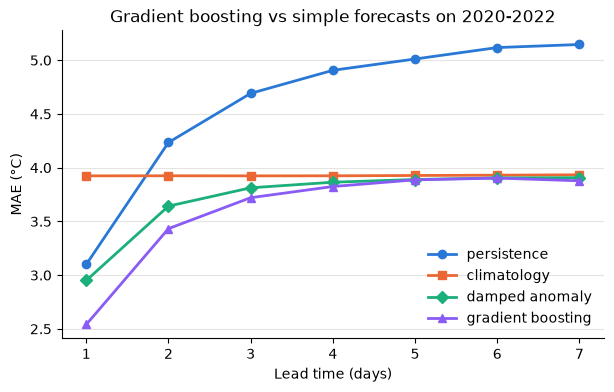

In [8]:
# Categorical slots 1-4 of the validated default palette; markers differ so identity is not color alone.
styles = {"persistence": ("#2a78d6", "o"), "climatology": ("#eb6834", "s"),
          "damped anomaly": ("#1baf7a", "D"), "gradient boosting": ("#8a5cf5", "^")}

fig, ax = plt.subplots(figsize=(7, 4))
for name, (color, marker) in styles.items():
    ax.plot(mae.index, mae[name], color=color, marker=marker, markersize=6, linewidth=2, label=name)
ax.set(xlabel="Lead time (days)", ylabel="MAE (°C)", title="Gradient boosting vs simple forecasts on 2020-2022", xticks=list(mae.index))
ax.grid(axis="y", color="#e5e4e0")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.show()

## Check: why there is no day-of-year feature

Trains lead 4 twice, with and without the day of year, and compares training and validation RMSE. A model that gets better on training years but worse on validation years is memorizing, not learning.

In [9]:
h, ahead = 4, pd.Timedelta(days=4)
y_train = train[f"y{h}"] - usual(train.STATION, train.DATE + ahead)
y_val = rows[f"y{h}"] - usual(rows.STATION, rows.DATE + ahead)
X4 = X.assign(clim_target=usual(data.STATION[keep], data.DATE[keep] + ahead))  # the lead 4 model's features
day = 2 * np.pi * data.DATE[keep].dt.day_of_year / 365.25
with_day = X4.assign(doy_sin=np.sin(day), doy_cos=np.cos(day))
check = {}
for name, features in {"without day of year": X4, "with day of year": with_day}.items():
    model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=0)
    model.fit(features[is_train], y_train)
    rmse_of = lambda pred, y: np.sqrt(((pred - y) ** 2).mean())
    check[name] = {"train RMSE": rmse_of(model.predict(features[is_train]), y_train),
                   "validation RMSE": rmse_of(model.predict(features[~is_train]), y_val)}
pd.DataFrame(check).T.round(2)

,train RMSE,validation RMSE
without day of year,4.10,5.17
with day of year,3.83,5.29


## Takeaways

* **Accuracy:** gradient boosting beats damped anomaly, the best simple forecast, at leads 1 to 3 (0.41 °C lower MAE at lead 1), and the luck test agrees. From lead 4 on it is level, and its RMSE is slightly worse at leads 5 to 7.
* **Vs random forest:** with the same inputs apart from the day of year, it is within 0.03 °C of the random forest at every lead, so the algorithm matters little so far.
* **Day of year:** adding it makes training error drop (RMSE 4.10 to 3.83 °C) and validation error rise (5.17 to 5.29 °C): the trees memorize past dates.
* **Next:** tune the learning rate, leaf size and L2 penalty.